# Fase 2 — Preprocesamiento y selección de variables

Queremos predecir al cierre de un día **D**, a las **23:59**, cuánto va a consumir el sistema de refrigeración en **D+1**. Cada fila final corresponde a un día de pronóstico.

Seguimos el recorrido de los dos borradores del equipo. De Genaro retomamos el control de las mediciones operativas, los ratios y las metas. De Lio retomamos los rezagos, las medias móviles y el análisis climático. Mostramos cómo se calcula cada paso con los datos del grupo. Al final comprobamos que los cálculos de esta notebook coincidan con el script de entrega.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Podemos abrir la notebook desde la raíz o desde la carpeta notebooks.
raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# Usamos los nombres y parámetros que también conoce el script de entrega.
from src.auxiliar_functions import SEMILLA, huella, verificar_checksums
from src.feature_engineering import HOJAS_OPERATIVAS, PROXIES
from src.features_planta import COLUMNAS_BASE
from src.seleccion_variables import ALPHA_LASSO, ALPHA_RIDGE, TOPE_BOSQUE

carpeta_procesados = raiz / "data" / "processed"
ruta_trabajo = carpeta_procesados / "dataset_trabajo.csv"
ruta_clima = raiz / "data" / "reference" / "clima_tecate_openmeteo.csv"
ruta_checksums = raiz / "data" / "checksums.json"
columna_frio = COLUMNAS_BASE["frio"]

# Las huellas verifican que cada integrante use la misma versión de los datos.
verificar_checksums()
with ruta_checksums.open(encoding="utf-8") as archivo:
    hashes_registrados = json.load(archivo)
assert huella(ruta_trabajo) == hashes_registrados["data/processed/dataset_trabajo.csv"]
assert huella(ruta_clima) == hashes_registrados["data/reference/clima_tecate_openmeteo.csv"]

Verificación de integridad completada: 3 archivo(s) coinciden.


## 2.1 · Limpieza del totalizador y de las predictoras

El script `python -m src.correccion_fechas` prepara el CSV horario y deja un registro por cada día excluido. Antes de unir, conserva la primera jornada real de los bloques apilados. En los solapamientos prioriza el Excel más reciente. Se excluyen días incompletos, cierres inválidos y fallas de reinicio o de medidor.

Para controlar saltos horarios se calibró con el primer año, hasta el 30/06/2021. El percentil 99,9 fue **4.956 kW** y se redondeó a **5.000 kW** para evitar que pocos kW definieran un descarte. El MAD de cierres también se calcula con ese primer año. Esa calibración conserva los **18 descartes** del equipo y el hash del CSV horario.

In [2]:
# Mostramos cuántas jornadas se descartaron por cada motivo.
ruta_descartes = carpeta_procesados / "tabla_dias_borrados.csv"
assert huella(ruta_descartes) == hashes_registrados["tabla_dias_borrados.csv"]
dias_descartados = pd.read_csv(ruta_descartes)
motivos = dias_descartados["Etapa_Filtro"].value_counts()
display(motivos.rename_axis("Motivo").to_frame("Días descartados"))

# Tres ejemplos concretos de la auditoría de EDA y la limpieza horaria.
ejemplos = ["2020-07-11", "2021-01-03", "2021-07-01"]
columnas = ["DIA", "Filas_Dia", "Frio_2359_kW", "Motivo_Detallado"]
display(dias_descartados.loc[dias_descartados["DIA"].isin(ejemplos), columnas])

,Días descartados
Motivo,
3. Falla de medidor (salto horario alto y cierre > 40.000 kW),5
1. Menor cantidad de horas (sin 23:59),5
1. Menor cantidad de horas (día incompleto < 24 hs),4
2. Sin reinicio del totalizador a medianoche (00:00),2
3. Falla de medidor (contador congelado),1
1. Sin dato válido en Frio (Kw) a las 23:59,1


,DIA,Filas_Dia,Frio_2359_kW,Motivo_Detallado
0,2020-07-11,25,29046.0,El totalizador no reinició a las 00:00 (00:00=...
1,2021-01-03,25,4925.0,Medidor congelado durante 10 hs (|inc|<=10 kW)...
2,2021-07-01,23,16411.0,El día tiene 23 lecturas válidas en Frio (Kw) ...


### Una fila por día y objetivo por fecha exacta

Filtramos las 23:59 porque los registros horarios son acumulados. Sumarlos contaría varias veces el mismo consumo. Para construir `y` buscamos el cierre en la fecha exacta **D+1**. Si mañana falta, la fila de hoy puede servir de historial, pero queda fuera de los ejemplos que tienen etiqueta.

In [3]:
# Filtramos el cierre y usamos la fecha para identificar cada fila.
datos_horarios = pd.read_csv(ruta_trabajo, parse_dates=["DIA"], low_memory=False)
diario = datos_horarios.loc[datos_horarios["HORA"] == "23:59"].drop(columns="HORA")
diario = diario.sort_values("DIA").set_index("DIA").copy()
assert diario.index.is_unique

# Un cierre negativo, ausente o infinito no puede actuar como dato de frío.
frio_por_dia = pd.to_numeric(diario[columna_frio], errors="coerce")
frio_por_dia = frio_por_dia.where(np.isfinite(frio_por_dia) & (frio_por_dia >= 0))

# reindex busca mañana por fecha. Si no existe esa fecha, devuelve NaN.
fecha_de_manana = diario.index + pd.Timedelta(days=1)
diario["y"] = frio_por_dia.reindex(fecha_de_manana).to_numpy()
diario.loc[frio_por_dia.isna(), "y"] = np.nan
pares_validos = diario.loc[diario["y"].notna()].copy()

print("Filas horarias:", len(datos_horarios))
print("Cierres diarios:", len(diario))
print("Pares sin etiqueta:", diario["y"].isna().sum())
print("Pares válidos:", len(pares_validos))
display(diario.loc["2020-07-09":"2020-07-12", [columna_frio, "y"]])

Filas horarias: 29296
Cierres diarios: 1172
Pares sin etiqueta: 32
Pares válidos: 1140


,Frio (Kw)_Consolidado EE,y
DIA,,
2020-07-09,30921.0,27721.0
2020-07-10,27721.0,NaN
2020-07-12,35721.0,31017.0


En el ejemplo, el **10 de julio** conserva su consumo de hoy. Como falta el cierre del **11 de julio**, su `y` queda sin valor aunque vuelva a haber una lectura el día 12.

### Corte 70/15/15

En el borrador de Genaro el reparto se calculaba antes de quitar las filas sin `y`. Repetimos ambos cálculos para ver dónde aparecía el desfase. A partir de acá usamos el reparto sobre pares válidos, igual que el script de Santino. Las fechas de la tabla son fechas **D**. Cuando se emite la primera predicción de Validation al cierre del 27/10, ya se conoce el cierre que actúa como última etiqueta de Train.

In [4]:
# Reproducimos el corte del borrador antes de filtrar las etiquetas.
fin_train_borrador = diario.index[round(len(diario) * 0.70) - 1]
print("Último D de Train si se cuentan los 1.172 cierres:", fin_train_borrador.date())

# Repartimos únicamente los días con un par D → D+1 válido.
n_train = round(len(pares_validos) * 0.70)
n_val = round(len(pares_validos) * 0.15)
train = pares_validos.iloc[:n_train]
validation = pares_validos.iloc[n_train:n_train + n_val]
test = pares_validos.iloc[n_train + n_val:]

filas_corte = []
for nombre, tramo in [("Train", train), ("Validation", validation), ("Test", test)]:
    filas_corte.append([nombre, len(tramo), tramo.index.min().date(), tramo.index.max().date()])
display(pd.DataFrame(filas_corte, columns=["Tramo", "Filas", "Primer D", "Último D"]))

# Conservamos los días intermedios sin y para usar su contexto hacia adelante.
diario_hasta_val = diario.loc[:validation.index.max()].drop(columns="y")
y_train = train["y"]
y_val = validation["y"]

Último D de Train si se cuentan los 1.172 cierres: 2022-10-27


,Tramo,Filas,Primer D,Último D
0,Train,798,2020-07-01,2022-10-26
1,Validation,171,2022-10-27,2023-04-29
2,Test,171,2023-04-30,2023-10-24


### Predictoras operativas · método de Genaro

Genaro partía de 28 mediciones identificadas durante EDA. Acá tomamos las hojas que tienen sentido operativo, así el ranking exploratorio de toda la serie no define el universo de candidatas. Los filtros se calculan con los mismos días de Train.

1. Convertimos negativos y valores mayores a **5 × el percentil 99 de Train** en faltantes.
2. Quitamos columnas con más de **20 % de faltantes** o sin variación.
3. Usamos **Spearman** para medir si el consumo futuro tiende a subir o bajar cuando cambia cada variable. El mínimo con `y` es **0,40** en valor absoluto. Se excluyen medidores que contienen Frío o casi lo duplican, con **|ρ| ≥ 0,98** con el frío de D. El frío observado en D sigue disponible por separado.
4. Ordenamos por la relación con `y` y dejamos un representante cuando dos predictoras tienen **|ρ| ≥ 0,90** entre sí.

In [5]:
# Tomamos columnas de las hojas operativas y evitamos los medidores duplicados.
candidatas_operativas = []
for columna in diario.columns:
    hoja = columna.rsplit("_", 1)[-1]
    if hoja in HOJAS_OPERATIVAS and columna not in PROXIES:
        candidatas_operativas.append(columna)

# Primero marcamos errores para que no influyan en la correlación.
operativas_train = train[candidatas_operativas].apply(pd.to_numeric, errors="coerce")
operativas_train = operativas_train.replace([np.inf, -np.inf], np.nan)
topes_train = operativas_train.quantile(0.99) * 5
fuera_de_rango = (operativas_train < 0) | (operativas_train > topes_train)
operativas_validas = operativas_train.mask(fuera_de_rango)

# Las comparaciones se calculan sobre los mismos días de Train.
faltantes_train = operativas_validas.isna().mean()
tienen_variacion = operativas_validas.nunique() > 1
aptas = faltantes_train.index[(faltantes_train <= 0.20) & tienen_variacion]
rho_manana = operativas_validas[aptas].corrwith(y_train, method="spearman")
rho_hoy = operativas_validas[aptas].corrwith(train[columna_frio], method="spearman")
buenas = rho_manana.index[(rho_manana.abs() >= 0.40) & (rho_hoy.abs() < 0.98)]
ranking = rho_manana[buenas].abs().sort_values(ascending=False, kind="stable")
correlacion_entre_columnas = operativas_validas[ranking.index].corr(method="spearman").abs()

# Buscamos de a una si la candidata se parece demasiado a una ya elegida.
operativas_elegidas = []
redundantes = {}
for columna in ranking.index:
    repetida = False
    for anterior in operativas_elegidas:
        if correlacion_entre_columnas.loc[columna, anterior] >= 0.90:
            redundantes[columna] = anterior
            repetida = True
            break
    if not repetida:
        operativas_elegidas.append(columna)

print("Candidatas por dominio:", len(candidatas_operativas))
print("Representantes elegidas:", len(operativas_elegidas))
tabla_operativas = pd.DataFrame({
    "Faltantes (%)": 100 * faltantes_train,
    "Spearman con Frío D": rho_hoy,
    "Spearman con Frío D+1": rho_manana,
})
display(tabla_operativas.loc[operativas_elegidas].round(3))
display(pd.Series(redundantes, name="Representante que se conservó").head(8).to_frame())

Candidatas por dominio:

 169
Representantes elegidas: 28


,Faltantes (%),Spearman con Frío D,Spearman con Frío D+1
KW Trafo 11_Totalizadores Energia,0.000,0.817,0.710
Agua Planta (Hl)_Consolidado Agua,0.000,0.779,0.688
KW Cond 5. 6 y 9_Totalizadores Energia,0.000,0.710,0.674
ET Servicios (Mj)_Consolidado GasVapor,0.000,-0.591,-0.594
KW Trafo 9_Totalizadores Energia,0.000,0.648,0.590
Vapor Servicio (Kg)_Consolidado GasVapor,0.000,-0.577,-0.577
KW Trafo 10_Totalizadores Energia,0.000,0.716,0.556
Aire Producido (M3)_Consolidado Aire,0.000,0.637,0.543
Agua Envasado (Hl)_Consolidado Agua,0.000,0.562,0.530
Elaboracion (Kw)_Consolidado EE,0.125,0.668,0.526


,Representante que se conservó
Planta de agua (Hl)_Consolidado Agua,Agua Planta (Hl)_Consolidado Agua
Produccion (Hl)_Consolidado Agua,Agua Planta (Hl)_Consolidado Agua
Tot_Vapor_CIP_Bodega_Consolidado GasVapor,Vapor Servicio (Kg)_Consolidado GasVapor
Kw Compresores Aire_Totalizadores Energia,Aire Producido (M3)_Consolidado Aire
KW Linea 3 y 4_Totalizadores Energia,KW Trafo 9_Totalizadores Energia
Aire (Kw)_Consolidado EE,Aire Producido (M3)_Consolidado Aire
Hl Cerveza Envasada_Consolidado Produccion,Envasado (Kw)_Consolidado EE
Linea 3 (Kw)_Consolidado EE,KW Linea 3_Totalizadores Energia


### Cómo se rellenan los faltantes

Primero arrastramos el último cierre válido hasta **tres días calendario**. Si el hueco es mayor, usamos la **mediana de Train**, calculada después de retirar lecturas imposibles. Reindexar a frecuencia diaria evita que tres filas separadas por un hueco cuenten como tres días seguidos. Mostramos qué cambia en Train. Luego aplicamos los mismos topes y medianas al historial necesario para Validation.

,Nulos originales,Imposibles,Nulos después
Elaboracion (Kw)_Consolidado EE,0,1,0
Envasado (Kw)_Consolidado EE,0,1,0
Bodega (Kw)_Consolidado EE,0,2,0
Pta Agua / Eflu (Kw)_Consolidado EE,0,5,0


Lecturas imposibles en Train: 9


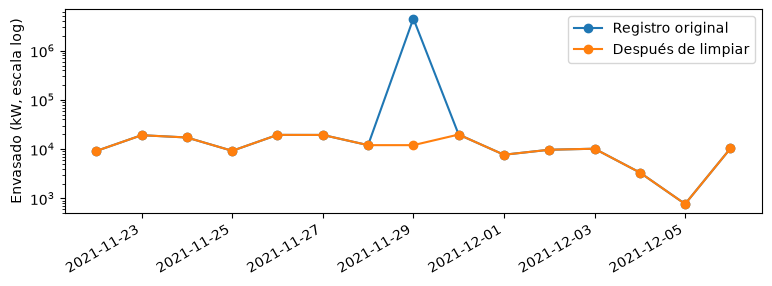

In [6]:
def rellenar_nulos(mediciones, medianas_train):
    """Completa hasta tres días hacia adelante y usa la mediana para lo que falte."""
    fechas = pd.date_range(mediciones.index.min(), mediciones.index.max(), freq="D")
    mediciones_por_dia = mediciones.reindex(fechas)
    con_arrastre = mediciones_por_dia.ffill(limit=3)
    return con_arrastre.reindex(mediciones.index).fillna(medianas_train)

# El historial conserva días sin y, que también pueden aportar una medición previa.
operativas_antes = diario_hasta_val[operativas_elegidas].apply(pd.to_numeric, errors="coerce")
operativas_antes = operativas_antes.replace([np.inf, -np.inf], np.nan)
topes = topes_train[operativas_elegidas]
es_imposible = (operativas_antes < 0) | (operativas_antes > topes)
operativas_sin_extremos = operativas_antes.mask(es_imposible)
medianas_operativas = operativas_sin_extremos.loc[train.index].median()
operativas_limpias = rellenar_nulos(operativas_sin_extremos, medianas_operativas)

# Resumen de cambios sobre los días supervisados de Train.
tabla_limpieza = pd.DataFrame({
    "Nulos originales": operativas_antes.loc[train.index].isna().sum(),
    "Imposibles": es_imposible.loc[train.index].sum(),
    "Nulos después": operativas_limpias.loc[train.index].isna().sum(),
})
hubo_cambios = (tabla_limpieza["Nulos originales"] + tabla_limpieza["Imposibles"]) > 0
display(tabla_limpieza.loc[hubo_cambios])
print("Lecturas imposibles en Train:", tabla_limpieza["Imposibles"].sum())

# Envasado tuvo una lectura de varios millones. Ilustramos su corrección.
columna_envasado = "Envasado (Kw)_Consolidado EE"
intervalo = slice("2021-11-22", "2021-12-06")
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(operativas_antes.loc[intervalo, columna_envasado], "o-", label="Registro original")
ax.plot(operativas_limpias.loc[intervalo, columna_envasado], "o-", label="Después de limpiar")
ax.set_yscale("log")
ax.set_ylabel("Envasado (kW, escala log)")
ax.legend()
fig.autofmt_xdate()
plt.show()

## 2.2A · Historial de frío y calendario, a partir del análisis de Lio

Un rezago de un día consulta **D−1**. Las medias de 3, 7 y 14 días incluyen D y requieren **2, 4 y 7** cierres observados. El desvío de siete días requiere cuatro cierres. Estos mínimos son los del borrador de Lio. Primero ponemos los huecos en el calendario y después usamos `shift` y `rolling`.

In [7]:
# Construimos un calendario con una fila por día, también donde falta el cierre.
fechas_hasta_val = pd.date_range(diario_hasta_val.index.min(), diario_hasta_val.index.max(), freq="D")
frio_en_calendario = frio_por_dia.reindex(fechas_hasta_val)
frio_en_calendario.index.name = "DIA"  # Conserva el nombre de la fecha al unir.
frio_historico = pd.DataFrame(index=fechas_hasta_val)

# shift mueve la serie: la fila D recibe el cierre del día anterior, o de hace 2 o 7 días.
frio_historico["frio_hoy_d"] = frio_en_calendario
frio_historico["frio_lag_1"] = frio_en_calendario.shift(1)
frio_historico["frio_lag_2"] = frio_en_calendario.shift(2)
frio_historico["frio_lag_7"] = frio_en_calendario.shift(7)
frio_historico["frio_roll_mean_3"] = frio_en_calendario.rolling(3, min_periods=2).mean()
frio_historico["frio_roll_mean_7"] = frio_en_calendario.rolling(7, min_periods=4).mean()
frio_historico["frio_roll_mean_14"] = frio_en_calendario.rolling(14, min_periods=7).mean()
frio_historico["frio_roll_std_7"] = frio_en_calendario.rolling(7, min_periods=4).std()

# El mes se conoce al emitir. El índice estacional vale más en el verano de Tecate.
frio_historico["mes_numero"] = frio_historico.index.month
angulo_del_mes = 2 * np.pi * frio_historico["mes_numero"] / 12
frio_historico["calor_estacional"] = (1 - np.cos(angulo_del_mes)) / 2
frio_antes = frio_historico.loc[diario_hasta_val.index]
medianas_frio = frio_antes.loc[train.index].median()
frio_limpio = rellenar_nulos(frio_antes, medianas_frio)

# Usamos el mismo rezago ya imputado para que la resta conserve su significado.
frio_limpio["frio_diff_1"] = frio_limpio["frio_hoy_d"] - frio_limpio["frio_lag_1"]
train_frio = frio_antes.loc[train.index]
tabla_frio = pd.DataFrame({
    "Faltantes antes": train_frio.isna().sum(),
    "Pearson con y": train_frio.corrwith(y_train),
    "Spearman con y": train_frio.corrwith(y_train, method="spearman"),
})
display(tabla_frio.round(3))

,Faltantes antes,Pearson con y,Spearman con y
frio_hoy_d,0,0.844,0.831
frio_lag_1,22,0.744,0.736
frio_lag_2,27,0.727,0.719
frio_lag_7,34,0.729,0.715
frio_roll_mean_3,6,0.829,0.817
frio_roll_mean_7,3,0.840,0.825
frio_roll_mean_14,6,0.839,0.827
frio_roll_std_7,3,0.115,0.105
mes_numero,0,-0.036,-0.085
calor_estacional,0,0.773,0.788


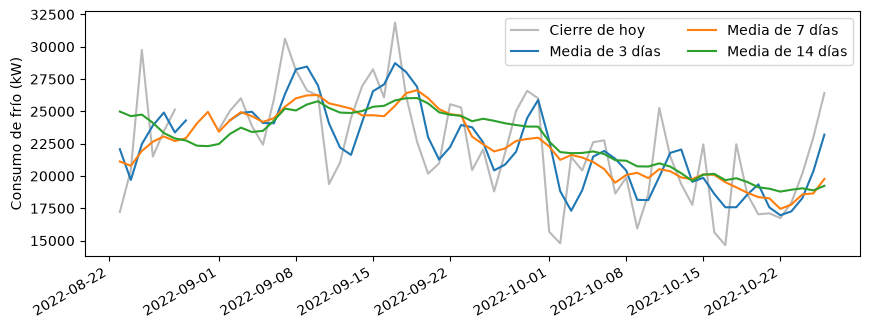

,Media de 3 días,Media de 7 días,Media de 14 días
Media de 3 días,1.000,0.950,0.923
Media de 7 días,0.950,1.000,0.974
Media de 14 días,0.923,0.974,1.000


In [8]:
# Un tramo corto muestra cómo las ventanas suavizan el cierre diario.
ventanas = ["frio_roll_mean_3", "frio_roll_mean_7", "frio_roll_mean_14"]
nombres_ventanas = ["Media de 3 días", "Media de 7 días", "Media de 14 días"]
fig, ax = plt.subplots(figsize=(10, 3.6))
ejemplo = frio_historico.loc[:train.index.max()].tail(65)
ax.plot(ejemplo["frio_hoy_d"], color="gray", alpha=0.55, label="Cierre de hoy")
for columna, etiqueta in zip(ventanas, nombres_ventanas):
    ax.plot(ejemplo[columna], label=etiqueta)
ax.set_ylabel("Consumo de frío (kW)")
ax.legend(ncols=2)
fig.autofmt_xdate()
plt.show()

# Una correlación alta señala que dos ventanas aportan información parecida.
correlacion_medias = frio_limpio.loc[train.index, ventanas].corr(method="spearman")
correlacion_medias.index = nombres_ventanas
correlacion_medias.columns = nombres_ventanas
display(correlacion_medias.round(3))

C:\Users\lioju\AppData\Local\Temp\ipykernel_22760\731839763.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  "Día de semana": train.index.dayofweek,
C:\Users\lioju\AppData\Local\Temp\ipykernel_22760\731839763.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  "Fin de semana": train.index.dayofweek >= 5,


,Variación explicada (%)
Mes,68.01
Día de semana,0.46
Fin de semana,0.07


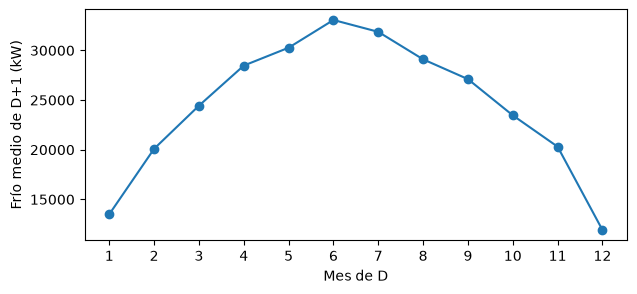

In [9]:
# El tamaño de efecto eta² separa la variación entre grupos de la variación total.
calendario_train = pd.DataFrame({
    "Mes": train.index.month,
    "Día de semana": train.index.dayofweek,
    "Fin de semana": train.index.dayofweek >= 5,
    "y": y_train,
}, index=train.index)
media_general = y_train.mean()
variacion_total = ((y_train - media_general) ** 2).sum()
efectos = {}
for columna in ["Mes", "Día de semana", "Fin de semana"]:
    grupos = calendario_train.groupby(columna)["y"].agg(["size", "mean"])
    variacion_entre_grupos = (grupos["size"] * (grupos["mean"] - media_general) ** 2).sum()
    efectos[columna] = 100 * variacion_entre_grupos / variacion_total
display(pd.Series(efectos, name="Variación explicada (%)").round(2).to_frame())

# La curva mensual permite ver la estacionalidad sin resumirla en una sola correlación.
consumo_por_mes = calendario_train.groupby("Mes")["y"].mean()
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(consumo_por_mes, marker="o")
ax.set(xlabel="Mes de D", ylabel="Frío medio de D+1 (kW)", xticks=range(1, 13))
plt.show()

Las tres medias se parecen mucho. Las ventanas cortas responden antes a cambios de operación y las largas suavizan más. La comparación de 2.3 mide qué aportan en conjunto. El mes muestra un efecto mucho mayor que el día de semana y el fin de semana. Conservamos las variables mensuales como candidatas.

### Temperatura y radiación de Tecate

Repetimos el análisis de Lio usando el mismo caché de Open-Meteo. Ahora medimos Pearson y Spearman solo en Train. `radiacion_roll7` es la media de **radiación solar**, mientras que `frio_roll_mean_7` es una media de **consumo de la planta**.

,Pearson con y,Spearman con y
radiacion_roll7,0.785,0.772
radiacion_roll3,0.768,0.761
radiacion_mj_m2,0.725,0.726
temp_aparente_c,0.558,0.558
temp_min_c,0.519,0.532
temp_media_roll7,0.533,0.531
temp_media_roll3,0.522,0.525
temp_media_c,0.513,0.515
temp_media_lag1,0.509,0.512
temp_max_roll3,0.508,0.507


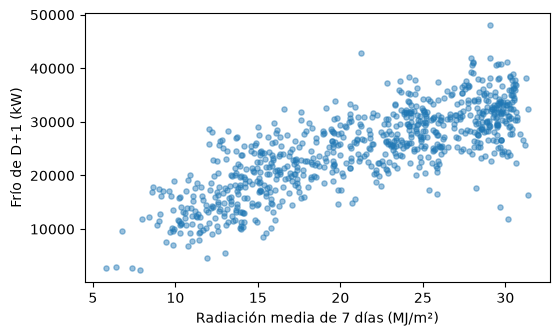

In [10]:
# El archivo histórico se conserva con su hash para repetir el diagnóstico.
clima = pd.read_csv(ruta_clima, parse_dates=["DIA"]).sort_values("DIA").set_index("DIA")
fechas_clima = pd.date_range(clima.index.min(), clima.index.max(), freq="D")
assert clima.index.equals(fechas_clima) and clima.notna().all().all()

# Replicamos las derivadas climáticas de Lio con ventanas hacia atrás.
clima["amplitud_termica_c"] = clima["temp_max_c"] - clima["temp_min_c"]
clima["temp_media_lag1"] = clima["temp_media_c"].shift(1)
clima["temp_media_roll3"] = clima["temp_media_c"].rolling(3, min_periods=1).mean()
clima["temp_media_roll7"] = clima["temp_media_c"].rolling(7, min_periods=1).mean()
clima["temp_max_roll3"] = clima["temp_max_c"].rolling(3, min_periods=1).mean()
clima["radiacion_roll3"] = clima["radiacion_mj_m2"].rolling(3, min_periods=1).mean()
clima["radiacion_roll7"] = clima["radiacion_mj_m2"].rolling(7, min_periods=1).mean()

clima_train = clima.loc[train.index]
tabla_clima = pd.DataFrame({
    "Pearson con y": clima_train.corrwith(y_train),
    "Spearman con y": clima_train.corrwith(y_train, method="spearman"),
}).sort_values("Spearman con y", ascending=False)
display(tabla_clima.round(3))

# Vemos el patrón entre radiación semanal y frío de mañana dentro de Train.
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(clima_train["radiacion_roll7"], y_train, s=14, alpha=0.45)
ax.set(xlabel="Radiación media de 7 días (MJ/m²)", ylabel="Frío de D+1 (kW)")
plt.show()

La radiación semanal queda entre las señales climáticas de mayor asociación. Su uso es exploratorio porque el archivo indica a qué fecha corresponde cada observación y queda pendiente verificar cuándo se podía consultar. Evaluarla para predicción requiere un dato equivalente disponible al cierre. El índice del mes sí se puede calcular con la fecha de D.

## 2.2B · Planta, ratios, metas e interacciones de Genaro

Un ratio compara dos cantidades de una forma que se puede interpretar. Para dividir exigimos un denominador positivo. Frío forma parte de Servicios, así que un cociente fuera de **[0, 1]** indica que los dos medidores requieren revisión. Ese cociente se trata como faltante.

Para la eficiencia usamos **EE Frío / Hl ÷ Meta EE Frío** de la hoja KPI. Un valor mayor a 1 indica un consumo por hectolitro superior a la meta. Cuando falta la meta usamos la mediana de metas positivas del mismo mes **en Train**. Guardamos un indicador para contar cuántas veces se sustituyó.

In [11]:
# Las columnas de Genaro son mediciones de las hojas originales del Excel.
frio = COLUMNAS_BASE["frio"]
servicios = COLUMNAS_BASE["servicios"]
bodega = COLUMNAS_BASE["bodega"]
elaboracion = COLUMNAS_BASE["elaboracion"]
agua_condensadores = COLUMNAS_BASE["agua_cond"]
agua_planta = COLUMNAS_BASE["agua_planta"]
produccion_bodega = COLUMNAS_BASE["hl_bodega"]
frio_por_hectolitro = COLUMNAS_BASE["ee_frio_hl"]
meta_frio = COLUMNAS_BASE["meta_frio"]

# Limpiamos las entradas antes de dividir o multiplicar.
columnas_planta = [frio, servicios, bodega, elaboracion, agua_planta,
                   produccion_bodega, frio_por_hectolitro]
planta_antes = diario_hasta_val[columnas_planta]
tope_planta = planta_antes.loc[train.index].quantile(0.99) * 5
planta_sin_extremos = planta_antes.mask((planta_antes < 0) | (planta_antes > tope_planta))
medianas_planta = planta_sin_extremos.loc[train.index].median()
planta_limpia = rellenar_nulos(planta_sin_extremos, medianas_planta)

# where deja la medición solo cuando cumple la condición de cada cociente.
tabla_planta = pd.DataFrame(index=diario_hasta_val.index)
servicios_positivos = planta_limpia[servicios].where(planta_limpia[servicios] > 0)
elaboracion_positiva = planta_limpia[elaboracion].where(planta_limpia[elaboracion] > 0)
agua_positiva = planta_limpia[agua_planta].where(planta_limpia[agua_planta] > 0)

ratio_frio = planta_limpia[frio] / servicios_positivos
tabla_planta["ratio_frio_servicios"] = ratio_frio.where(ratio_frio.between(0, 1))
tabla_planta["ratio_bodega_elaboracion"] = planta_limpia[bodega] / elaboracion_positiva
agua_cond = diario_hasta_val[agua_condensadores].where(diario_hasta_val[agua_condensadores] >= 0)
tabla_planta["ratio_aguacond_aguaplanta"] = agua_cond / agua_positiva

# Las metas originales están expresadas por hectolitro.
meta_observada = diario_hasta_val[meta_frio].where(diario_hasta_val[meta_frio] > 0)
meta_por_mes = meta_observada.loc[train.index].groupby(train.index.month).median()
mes_de_cada_dia = pd.Series(diario_hasta_val.index.month, index=diario_hasta_val.index)
meta_usada = meta_observada.fillna(mes_de_cada_dia.map(meta_por_mes))
tabla_planta["meta_frio_imputada"] = meta_observada.isna().astype(int)
tabla_planta["eficiencia_frio_vs_meta"] = planta_limpia[frio_por_hectolitro] / meta_usada.where(meta_usada > 0)

print("Cocientes Frío/Servicios mayores a 1 en Train:", (ratio_frio.loc[train.index] > 1).sum())
print("Metas sustituidas en Train:", tabla_planta.loc[train.index, "meta_frio_imputada"].sum())
display(meta_por_mes.rename("Meta típica de Train").round(2).to_frame())

Cocientes Frío/Servicios mayores a 1 en Train: 2
Metas sustituidas en Train: 348


,Meta típica de Train
DIA,
1,3.01
2,2.51
3,2.43
4,2.43
5,2.47
6,2.47
7,3.23
8,3.35
9,2.93


,Faltantes (%),Spearman con y
ratio_frio_servicios,0.251,0.716
ratio_bodega_elaboracion,0.000,0.038
ratio_aguacond_aguaplanta,43.609,-0.121
meta_frio_imputada,0.000,0.033
eficiencia_frio_vs_meta,0.000,0.308
bodega_x_temp_media_c,0.000,0.689
bodega_x_radiacion_roll7,0.000,0.767
bodega_x_calor_estacional,0.000,0.796


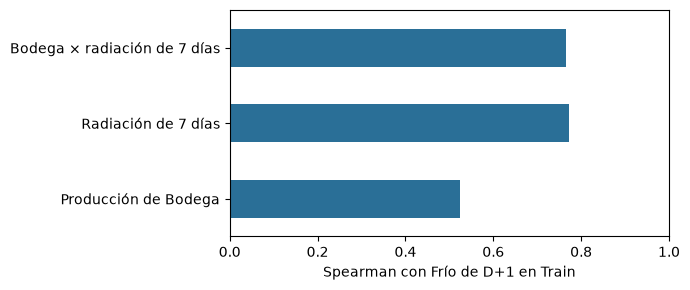

In [12]:
# Calculamos las interacciones de Genaro para el diagnóstico.
tabla_planta["bodega_x_temp_media_c"] = planta_limpia[produccion_bodega] * clima["temp_media_c"]
tabla_planta["bodega_x_radiacion_roll7"] = planta_limpia[produccion_bodega] * clima["radiacion_roll7"]

# La interacción que podemos calcular al cierre usa producción y el mes de D.
tabla_planta["bodega_x_calor_estacional"] = planta_limpia[produccion_bodega] * frio_antes["calor_estacional"]

planta_train = tabla_planta.loc[train.index]
diagnostico_planta = pd.DataFrame({
    "Faltantes (%)": 100 * planta_train.isna().mean(),
    "Spearman con y": planta_train.corrwith(y_train, method="spearman"),
})
display(diagnostico_planta.round(3))

# Comparamos la interacción climática con sus componentes en los mismos días.
comparar_interaccion = pd.DataFrame({
    "Producción de Bodega": planta_limpia.loc[train.index, produccion_bodega],
    "Radiación de 7 días": clima_train["radiacion_roll7"],
    "Bodega × radiación de 7 días": planta_train["bodega_x_radiacion_roll7"],
})
fig, ax = plt.subplots(figsize=(7, 3))
comparar_interaccion.corrwith(y_train, method="spearman").plot.barh(ax=ax, color="#2a6f97")
ax.set(xlabel="Spearman con Frío de D+1 en Train", xlim=(0, 1))
fig.tight_layout()
plt.show()

La interacción con radiación muestra una asociación alta, parecida a la de la radiación sola. Para saber si agrega información al modelo habría que compararla en Validation con una fuente disponible a la hora de pronosticar. Agua de condensadores tiene un tramo largo sin datos y su ratio queda para diagnóstico. El indicador de meta sustituida sirve para interpretar el cálculo. Llevamos a 2.3 los dos ratios de energía, la eficiencia y la interacción con el índice estacional.

In [13]:
# Juntamos las variables que podríamos conocer al final del día D.
columnas_planta_modelo = [
    "ratio_frio_servicios", "ratio_bodega_elaboracion",
    "eficiencia_frio_vs_meta", "bodega_x_calor_estacional",
]
planta_para_modelo = tabla_planta[columnas_planta_modelo]
medianas_derivadas = planta_para_modelo.loc[train.index].median()
planta_completa = rellenar_nulos(planta_para_modelo, medianas_derivadas)

# Las etiquetas y se mantienen separadas de las columnas que entran al modelo.
predictoras = pd.concat([operativas_limpias, frio_limpio, planta_completa], axis=1)
X_train = predictoras.loc[train.index]
X_val = predictoras.loc[validation.index]
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_val.to_numpy()).all()

display(pd.DataFrame({
    "Grupo": ["Mediciones operativas", "Historial de frío y calendario", "Derivadas de planta"],
    "Columnas": [operativas_limpias.shape[1], frio_limpio.shape[1], planta_completa.shape[1]],
}))
print("Candidatas totales:", X_train.shape[1])

,Grupo,Columnas
0,Mediciones operativas,28
1,Historial de frío y calendario,11
2,Derivadas de planta,4


Candidatas totales: 43


## 2.3 · Selección de variables

Probamos dos métodos con las **mismas filas de Train**.

- **LASSO** primero estandariza las columnas. Con una penalización `alpha` fijada en 100, algunos coeficientes se vuelven cero. Las variables con coeficiente distinto de cero forman su propuesta.
- **Random Forest** asigna importancia según cuánto ayudan las columnas a reducir el error cuadrático dentro de los árboles. Tomamos sus 12 primeras. Con columnas correlacionadas conviene mirar también la comparación en Validation, porque pueden repartirse la importancia.

El frío de hoy está disponible al emitir. Lo incluimos en todas las alternativas para comparar las señales adicionales sobre la misma referencia.

In [14]:
# Método 1. El escalador y LASSO aprenden únicamente de Train.
modelo_lasso = Pipeline([
    ("escalador", StandardScaler()),
    ("lasso", Lasso(alpha=ALPHA_LASSO, max_iter=30000, random_state=SEMILLA)),
])
modelo_lasso.fit(X_train, y_train)
coeficientes = pd.Series(modelo_lasso.named_steps["lasso"].coef_, index=X_train.columns)

# Método 2. Medimos la importancia con un bosque ajustado en el mismo Train.
modelo_bosque = RandomForestRegressor(
    n_estimators=200, max_depth=8, min_samples_leaf=6, n_jobs=1, random_state=SEMILLA,
)
modelo_bosque.fit(X_train, y_train)
importancia = pd.Series(modelo_bosque.feature_importances_, index=X_train.columns)
mejores_del_bosque = importancia.sort_values(ascending=False, kind="stable").head(TOPE_BOSQUE)

tabla_seleccion = pd.DataFrame({
    "Coeficiente LASSO": coeficientes,
    "Importancia bosque": importancia,
    "LASSO": coeficientes != 0,
    "Random Forest": importancia.index.isin(mejores_del_bosque.index),
})
tabla_seleccion["Intersección"] = tabla_seleccion["LASSO"] & tabla_seleccion["Random Forest"]
display(tabla_seleccion.sort_values("Importancia bosque", ascending=False).head(12).round(4))

,Coeficiente LASSO,Importancia bosque,LASSO,Random Forest,Intersección
frio_roll_mean_7,12.2911,0.4110,True,True,True
frio_hoy_d,1663.0015,0.2913,True,True,True
frio_roll_mean_14,2551.7536,0.0931,True,True,True
frio_roll_mean_3,0.0000,0.0319,False,True,False
bodega_x_calor_estacional,0.0000,0.0300,False,True,False
frio_diff_1,382.4963,0.0098,True,True,True
KW Linea 3_Totalizadores Energia,0.0000,0.0070,False,True,False
Red Paste L4_Consolidado Agua,187.0913,0.0058,True,True,True
ratio_frio_servicios,335.5017,0.0056,True,True,True
KW Secador Kaeser_Totalizadores Energia,307.5762,0.0055,True,True,True


### Elegimos el subconjunto con Validation

Probamos todas las candidatas, la propuesta de cada selector y su intersección. Usamos **el mismo Ridge con `alpha=10`** para que la diferencia sea el conjunto de columnas. Cada pipeline estandariza a partir de Train. Elegimos el menor **MAE de Validation** y, en caso de empate a 0,01 kW, el conjunto más corto. Test queda reservado para el modelo final de la fase siguiente.

,Subconjunto,Columnas,MAE Validation (kW)
0,Random Forest,12,2149.43
1,Intersección,9,2227.85
2,LASSO,22,2286.60
3,Todas,43,2286.66


,Coeficiente LASSO,Importancia bosque,LASSO,Random Forest,Intersección
ET Servicios (Mj)_Consolidado GasVapor,-184.1526,0.0053,True,True,True
KW Secador Kaeser_Totalizadores Energia,307.5762,0.0055,True,True,True
KW Linea 3_Totalizadores Energia,0.0000,0.0070,False,True,False
Red Paste L4_Consolidado Agua,187.0913,0.0058,True,True,True
KW Trafo 12_Totalizadores Energia,280.7422,0.0050,True,True,True
frio_hoy_d,1663.0015,0.2913,True,True,True
frio_roll_mean_3,0.0000,0.0319,False,True,False
frio_roll_mean_7,12.2911,0.4110,True,True,True
frio_roll_mean_14,2551.7536,0.0931,True,True,True
frio_diff_1,382.4963,0.0098,True,True,True


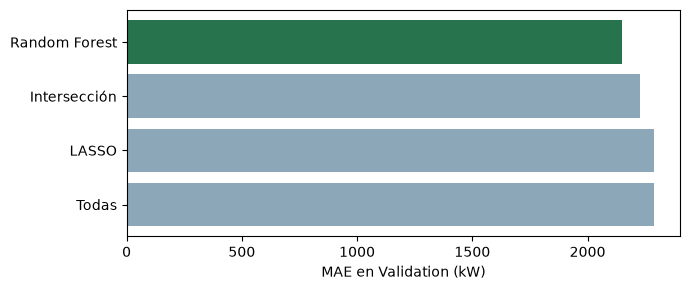

In [15]:
# Armamos las listas en el mismo orden de columnas que tiene el CSV.
grupos = {"Todas": X_train.columns.tolist()}
for nombre in ["LASSO", "Random Forest", "Intersección"]:
    elegidas = tabla_seleccion[nombre] | (tabla_seleccion.index == "frio_hoy_d")
    grupos[nombre] = tabla_seleccion.index[elegidas].tolist()

# Probamos cada grupo con el mismo Ridge y las mismas fechas.
resultados = []
for nombre, columnas in grupos.items():
    modelo = Pipeline([
        ("escalador", StandardScaler()),
        ("ridge", Ridge(alpha=ALPHA_RIDGE, random_state=SEMILLA)),
    ])
    modelo.fit(X_train[columnas], y_train)
    prediccion = modelo.predict(X_val[columnas])
    error = mean_absolute_error(y_val, prediccion)
    resultados.append([nombre, len(columnas), round(error, 2)])

comparacion = pd.DataFrame(resultados, columns=["Subconjunto", "Columnas", "MAE Validation (kW)"])
comparacion = comparacion.sort_values(["MAE Validation (kW)", "Columnas", "Subconjunto"])
ganador = comparacion.iloc[0]["Subconjunto"]
columnas_finales = grupos[ganador]
display(comparacion.reset_index(drop=True))
display(tabla_seleccion.loc[columnas_finales].round(4))

# Graficamos el MAE para ver la distancia entre los cuatro conjuntos.
fig, ax = plt.subplots(figsize=(7, 3))
colores = ["#26734d" if nombre == ganador else "#8ca8b8" for nombre in comparacion["Subconjunto"]]
ax.barh(comparacion["Subconjunto"], comparacion["MAE Validation (kW)"], color=colores)
ax.invert_yaxis()
ax.set_xlabel("MAE en Validation (kW)")
fig.tight_layout()
plt.show()

In [16]:
# La correlación de dos medias motiva medir cuánto cambia el error si quitamos una.
resultados_medias = []
for nombre, ventanas_usadas in [("3, 7 y 14", ventanas), ("3 y 14", [ventanas[0], ventanas[2]]),
                                ("Solo 14", [ventanas[2]])]:
    columnas = []
    for columna in columnas_finales:
        if columna not in ventanas or columna in ventanas_usadas:
            columnas.append(columna)
    modelo = Pipeline([
        ("escalador", StandardScaler()),
        ("ridge", Ridge(alpha=ALPHA_RIDGE, random_state=SEMILLA)),
    ])
    modelo.fit(X_train[columnas], y_train)
    prediccion = modelo.predict(X_val[columnas])
    error = mean_absolute_error(y_val, prediccion)
    resultados_medias.append([nombre, len(columnas), round(error, 2)])
display(pd.DataFrame(resultados_medias, columns=["Medias (días)", "Columnas", "MAE Validation (kW)"]))

,Medias (días),Columnas,MAE Validation (kW)
0,"3, 7 y 14",12,2149.43
1,3 y 14,11,2161.15
2,Solo 14,10,2193.52


La comparación elige el conjunto propuesto por Random Forest. El error de la tabla corresponde a **Ridge evaluando cada conjunto**. Las tres medias permanecen en las 12 columnas y hay dos alternativas más chicas para contrastar por familia de modelo en Fase 3. La media de siete días también se calcula por separado en el baseline obligatorio.

## 2.4 · Exportación, escala y linaje

Primero comprobamos que el script de entrega reconstruya las variables y la decisión que mostramos. Guardamos los CSV en unidades originales. Ajustamos `StandardScaler` dentro de un `Pipeline` con `X_train` y verificamos sus parámetros. La fecha de ejecución, las transformaciones, las shapes y los hashes quedan en `data_lineage.json`.

In [17]:
# Ejecutamos el mismo script reproducible que se puede llamar desde la terminal.
from src.preprocessing_pipeline import run_pipeline

resultado_script = run_pipeline()

# Comprobamos los resultados antes de mirar los archivos exportados.
pd.testing.assert_frame_equal(resultado_script["X_train_candidatas"], X_train, check_freq=False)
assert resultado_script["X_train"].columns.tolist() == columnas_finales
val_notebook = X_val[columnas_finales].reset_index(drop=True)
pd.testing.assert_frame_equal(resultado_script["X_val"], val_notebook)
y_notebook = y_val.reset_index(drop=True)
pd.testing.assert_series_equal(resultado_script["y_val"], y_notebook)

# La media aprendida por el escalador debe coincidir con la de Train.
escalador = resultado_script["scaler_pipeline"].named_steps["scaler"]
np.testing.assert_allclose(escalador.mean_, resultado_script["X_train"].mean())
assert escalador.n_samples_seen_ == len(train)

SECCIÓN 2.4 — RESUMEN DE PREPARACIÓN Y VERSIONADO DE DATOS
Días iniciales                  : 1172
Días con registro 23:59         : 1172
Días descartados (sin 23:59)    : 0
Observaciones descartadas (D+1) : 32 (discontinuidad/último día=32, cierre inválido D+1=0, solo cierre D inválido=0)
Observaciones con target válido : 1140
--------------------------------------------------------------------------------
TRAIN      | n= 798 (70.00%) | X=[798, 12] | y=[798] | 2020-07-01 -> 2022-10-26
VALIDATION | n= 171 (15.00%) | X=[171, 12] | y=[171] | 2022-10-27 -> 2023-04-29
TEST       | n= 171 (15.00%) | X=[171, 12] | y=[171] | 2023-04-30 -> 2023-10-24
--------------------------------------------------------------------------------
Checksums SHA-256 generados:
  dataset_diario_base.csv  : dc8b215bb583e9c082512a2d7488b57616382e28ca7b7e9a170f364df1c00a3b
  dataset_final.csv        : 2d023012ed97d340f30d79d57744c71fd8575ac03b0b56347bad3817932b6228
  train.csv                : b0f285a1fce335b4762f51a

In [18]:
# Las tres particiones y la base diaria quedan escritas en data/processed.
archivos_generados = resultado_script["summary"]["exported_paths"]
for nombre, ruta in archivos_generados.items():
    clave = f"data/processed/{nombre}"
    assert huella(Path(ruta)) == hashes_registrados[clave], f"Cambió la huella de {nombre}"

# Verificamos el archivo final con las columnas en unidades originales.
ruta_final = carpeta_procesados / "dataset_final.csv"
csv_final = pd.read_csv(ruta_final, parse_dates=["DIA"])
pd.testing.assert_frame_equal(csv_final, resultado_script["df_final"], check_dtype=False)
assert csv_final["DIA"].is_unique and csv_final.notna().all().all()

# Mostramos las dimensiones que pide la consigna.
for nombre, clave in [("Train", "X_train"), ("Validation", "X_val"), ("Test", "X_test")]:
    print(nombre, resultado_script[clave].shape)
print("SHA-256 de dataset_final.csv:", huella(ruta_final))

Train (798, 12)
Validation (171, 12)
Test (171, 12)
SHA-256 de dataset_final.csv: 2d023012ed97d340f30d79d57744c71fd8575ac03b0b56347bad3817932b6228


Quedan **1.140 pares diarios**. El notebook muestra cómo llegamos a la lista de variables y el script reproduce los mismos CSV sin escalar. La Fase 3 puede comparar modelos con estas mismas fechas y nombres de columnas.